# Appendix B: calibration of $g_y^*$ and $g_z^*$

This notebook explains and reproduces the gain calibration in Appendix B of `preregistration_revised.tex`. The constants contain no psychological parameter: they only put $\gamma_y$ and $\gamma_z$ into benchmark units.

The notebook follows the appendix from the target benchmark ratios to the Monte Carlo estimates produced by the screened stimulus generator.

## Roadmap

1. Define the benchmark weight ratios.
2. Show why the long-run pair score has the same mean as the agreement signal.
3. Reduce the six source pairs to coupled, mixed, and independent roles.
4. Derive the truth and hidden-source score gaps.
5. Estimate those gaps with the production generator.
6. Convert the gaps into $g_y^*$ and $g_z^*$ and verify the resulting ratios.
7. Inspect Monte Carlo precision and convergence.

## 1. Target benchmark ratios

For two softmax-weighted sources $a$ and $b$,

$$
\frac{w_a}{w_b}=\exp\left[g(\eta_a-\eta_b)\right].
$$

The truth-estimation branch should reproduce the independent-to-coupled benchmark ratio

$$R_y=1+\lambda,$$

while the hidden-source branch should reproduce the visible-partner-to-other ratio

$$R_z=\frac{1+2\lambda}{1-\lambda}.$$

If the expected score gap is $\delta$, setting $\exp(g^*\delta)=R$ gives $g^*=\log(R)/\delta$.

In [1]:
from dataclasses import replace
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "coupling_sources").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from coupling_sources.core.data import StimulusSpec
from coupling_sources.core.gain_calibration import (
    calibrate_gain_constants,
    gain_calibration_design,
    gain_calibration_stability,
)

MC_SEED = 20260711
N_MONTE_CARLO_REPLICATES = 2000
CALIBRATION_SPEC = StimulusSpec(
    seed=MC_SEED,
    n_participants=N_MONTE_CARLO_REPLICATES,
    n_sources=4,
    n_rounds=1,
    n_trials_full=28,
    n_trials_partial=12,
    sigma=0.55,
    lam=0.8,
    coupled_sources=(0, 1),
    resultant_floor_full=0.6,
    resultant_floor_leave_one_out=0.6,
)

{
    "seed": MC_SEED,
    "n_monte_carlo_replicates": N_MONTE_CARLO_REPLICATES,
    **gain_calibration_design(CALIBRATION_SPEC),
}

{'seed': 20260711,
 'n_monte_carlo_replicates': 2000,
 'n_sources': 4,
 'n_trials_full': 28,
 'n_trials_partial': 12,
 'sigma': 0.55,
 'lam': 0.8,
 'coupled_sources': [0, 1],
 'resultant_floor_full': 0.6,
 'resultant_floor_leave_one_out': 0.6}

In [2]:
lam = CALIBRATION_SPEC.lam
target_ratio_y = 1.0 + lam
target_ratio_z = (1.0 + 2.0 * lam) / (1.0 - lam)

print(f"R_y = 1 + lambda = {target_ratio_y:.3f}")
print(f"R_z = (1 + 2 lambda) / (1 - lambda) = {target_ratio_z:.3f}")

R_y = 1 + lambda = 1.800
R_z = (1 + 2 lambda) / (1 - lambda) = 13.000


## 2. Why the learning rate drops out of the calibration

A visible pair is updated as

$$c_t=(1-\alpha)c_{t-1}+\alpha s_t.$$

At stationarity, let $\bar c=\mathbb{E}[c_t]=\mathbb{E}[c_{t-1}]$ and $\bar s=\mathbb{E}[s_t]$. Then

$$\bar c=(1-\alpha)\bar c+\alpha\bar s \quad\Longrightarrow\quad \bar c=\bar s.$$

Thus $\alpha$ controls how quickly and noisily scores move, but not their long-run means. The gain calibration therefore needs the expected agreement signals, not a chosen learning rate.

## 3. Three structural pair roles

With coupled sources 0 and 1 and independent sources 2 and 3, the six pairs reduce to three roles:

| Role | Pairs | Long-run mean |
|---|---|---|
| Coupled $\mathrm C$ | $(0,1)$ | $\bar s_{\mathrm C}$ |
| Mixed $\mathrm X$ | $(0,2),(0,3),(1,2),(1,3)$ | $\bar s_{\mathrm X}$ |
| Independent $\mathrm I$ | $(2,3)$ | $\bar s_{\mathrm I}$ |

The relative-agreement signal is

$$s_{ij,t}=\frac12\left[\cos(x_{it}-x_{jt})-\frac{1}{|P_t|}\sum_{\{k,\ell\}\in P_t}\cos(x_{kt}-x_{\ell t})\right].$$

It compares a pair's cosine agreement with the mean agreement among all currently visible pairs. Resultant screens and the truth/probe mixture alter its expectation, so the three means are estimated from the actual generator.

In [3]:
calibration = calibrate_gain_constants(CALIBRATION_SPEC)

print("Role            mean signal      MC SE")
print("----------------------------------------")
for label, mean_name in (
    ("coupled", "s_coupled"),
    ("mixed", "s_mixed"),
    ("independent", "s_independent"),
):
    mean = getattr(calibration, mean_name)
    se = getattr(calibration, f"{mean_name}_se")
    print(f"{label:<14} {mean:>11.6f}   {se:.6f}")

Role            mean signal      MC SE
----------------------------------------
coupled           0.075542   0.000339
mixed            -0.015669   0.000141
independent      -0.012866   0.000458


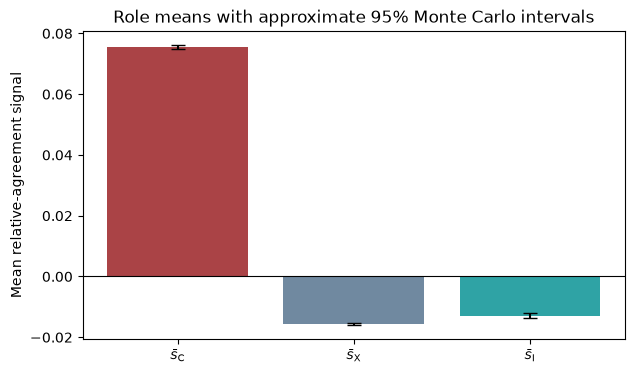

In [4]:
role_labels = [r"$\bar{s}_{\mathrm{C}}$", r"$\bar{s}_{\mathrm{X}}$", r"$\bar{s}_{\mathrm{I}}$"]
role_means = [calibration.s_coupled, calibration.s_mixed, calibration.s_independent]
role_ses = [calibration.s_coupled_se, calibration.s_mixed_se, calibration.s_independent_se]

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(role_labels, role_means, color=["#9b2226", "#577590", "#0a9396"], alpha=0.85)
ax.errorbar(role_labels, role_means, yerr=np.asarray(role_ses) * 1.96, fmt="none", color="black", capsize=5)
ax.axhline(0.0, color="black", linewidth=0.8)
ax.set_ylabel("Mean relative-agreement signal")
ax.set_title("Role means with approximate 95% Monte Carlo intervals")
plt.show()

## 4. Branch-specific score gaps

For truth estimation, a coupled source belongs to one coupled and two mixed pairs, while an independent source belongs to one independent and two mixed pairs. Because $\eta_i^y$ is the negative mean of the source's three pair scores, the mixed terms cancel:

$$\delta_y=\eta^y_{\mathrm{independent}}-\eta^y_{\mathrm{coupled}}=\frac{\bar s_{\mathrm C}-\bar s_{\mathrm I}}{3}.$$

For a hidden coupled source, its visible partner carries the coupled-pair score and either unrelated visible source carries a mixed-pair score:

$$\delta_z=\eta^z_{\mathrm{partner}}-\eta^z_{\mathrm{other}}=\bar s_{\mathrm C}-\bar s_{\mathrm X}.$$

In [5]:
delta_y_from_roles = (calibration.s_coupled - calibration.s_independent) / 3.0
delta_z_from_roles = calibration.s_coupled - calibration.s_mixed

np.testing.assert_allclose(delta_y_from_roles, calibration.delta_y)
np.testing.assert_allclose(delta_z_from_roles, calibration.delta_z)

print(f"delta_y = (s_C - s_I) / 3 = {calibration.delta_y:.6f} (MC SE {calibration.delta_y_se:.6f})")
print(f"delta_z = s_C - s_X       = {calibration.delta_z:.6f} (MC SE {calibration.delta_z_se:.6f})")

delta_y = (s_C - s_I) / 3 = 0.029469 (MC SE 0.000191)
delta_z = s_C - s_X       = 0.091210 (MC SE 0.000438)


## 5. Convert score gaps to gains

Substituting each target ratio and expected score gap into $g^*=\log(R)/\delta$ gives

$$g_y^*=\frac{\log(1+\lambda)}{\delta_y}, \qquad g_z^*=\frac{\log[(1+2\lambda)/(1-\lambda)]}{\delta_z}.$$

The truth gain is not expected to equal the hidden-source gain because the two branches use different score gaps and target ratios.

In [6]:
g_star_y_from_formula = np.log(target_ratio_y) / calibration.delta_y
g_star_z_from_formula = np.log(target_ratio_z) / calibration.delta_z

np.testing.assert_allclose(g_star_y_from_formula, calibration.g_star_y)
np.testing.assert_allclose(g_star_z_from_formula, calibration.g_star_z)

print(f"g_y* = {calibration.g_star_y:.6f} (MC SE {calibration.g_star_y_se:.6f}; locked value {calibration.g_star_y:.3f})")
print(f"g_z* = {calibration.g_star_z:.6f} (MC SE {calibration.g_star_z_se:.6f}; locked value {calibration.g_star_z:.3f})")

g_y* = 19.945700 (MC SE 0.129431; locked value 19.946)
g_z* = 28.121211 (MC SE 0.134989; locked value 28.121)


## 6. Verify the benchmark-unit interpretation

The fitted gains are $g_y=\gamma_y g_y^*$ and $g_z=\gamma_z g_z^*$. Therefore the expected ratios are

$$\exp(\gamma_y g_y^*\delta_y)=R_y^{\gamma_y}, \qquad \exp(\gamma_z g_z^*\delta_z)=R_z^{\gamma_z}.$$

Consequently $\gamma=0$ gives equal weights, $\gamma=1$ gives the benchmark ratio, intermediate values interpolate on the log-ratio scale, and negative values reverse the direction.

In [7]:
recovered_ratio_y = np.exp(calibration.g_star_y * calibration.delta_y)
recovered_ratio_z = np.exp(calibration.g_star_z * calibration.delta_z)
np.testing.assert_allclose(recovered_ratio_y, target_ratio_y)
np.testing.assert_allclose(recovered_ratio_z, target_ratio_z)

print("gamma    truth ratio    hidden-source ratio")
print("-------------------------------------------")
for gamma in (-1.0, 0.0, 0.5, 1.0):
    ratio_y = np.exp(gamma * calibration.g_star_y * calibration.delta_y)
    ratio_z = np.exp(gamma * calibration.g_star_z * calibration.delta_z)
    print(f"{gamma:>5.1f}    {ratio_y:>11.4f}    {ratio_z:>19.4f}")

gamma    truth ratio    hidden-source ratio
-------------------------------------------
 -1.0         0.5556                 0.0769
  0.0         1.0000                 1.0000
  0.5         1.3416                 3.6056
  1.0         1.8000                13.0000


## 7. Monte Carlo stability

The `_se` quantities describe uncertainty from using a finite number of generated trial-list replicates. They are not participant uncertainty or posterior uncertainty. The gain standard errors use first-order propagation through $g^*=\log(R)/\delta$.

The locked run uses 2,000 independent trial-list replicates. Here a 1% maximum relative Monte Carlo SE is used as an explicit diagnostic threshold.

In [8]:
stability = gain_calibration_stability(calibration)
MAX_RELATIVE_MC_SE = 0.01

print(f"g_y* relative MC SE: {stability.g_star_y_relative_mc_se:.3%}")
print(f"g_z* relative MC SE: {stability.g_star_z_relative_mc_se:.3%}")
print(f"g_y* approximate 95% MC interval: {stability.g_star_y_mc_interval_95}")
print(f"g_z* approximate 95% MC interval: {stability.g_star_z_mc_interval_95}")
print(f"maximum relative MC SE: {stability.max_relative_mc_se:.3%}")
print("stability check:", "PASS" if stability.max_relative_mc_se <= MAX_RELATIVE_MC_SE else "FAIL")

assert stability.max_relative_mc_se <= MAX_RELATIVE_MC_SE

g_y* relative MC SE: 0.649%
g_z* relative MC SE: 0.480%
g_y* approximate 95% MC interval: (19.692014506534, 20.19938595421312)
g_z* approximate 95% MC interval: (27.85663204015848, 28.38579077802372)
maximum relative MC SE: 0.649%
stability check: PASS


## 8. Convergence as Monte Carlo replication increases

The following diagnostic recalibrates at smaller replication counts using the same seed. The estimates need not move monotonically, but their Monte Carlo intervals should narrow approximately at the usual $1/\sqrt{N}$ rate. The 2,000-replicate result is reused from above.

N= 100: g_y*=  19.848 +/- 1.230, g_z*=  27.992 +/- 1.194


N= 500: g_y*=  20.133 +/- 0.503, g_z*=  27.863 +/- 0.541
N=2000: g_y*=  19.946 +/- 0.254, g_z*=  28.121 +/- 0.265


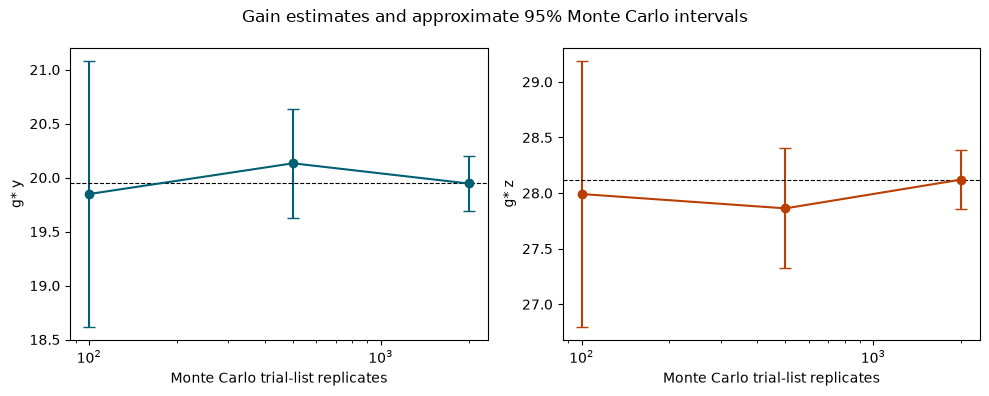

In [9]:
replicate_counts = (100, 500, N_MONTE_CARLO_REPLICATES)
convergence = []
for count in replicate_counts:
    estimate = (
        calibration
        if count == N_MONTE_CARLO_REPLICATES
        else calibrate_gain_constants(replace(CALIBRATION_SPEC, n_participants=count))
    )
    convergence.append(estimate)
    print(
        f"N={count:>4}: "
        f"g_y*={estimate.g_star_y:>8.3f} +/- {1.96 * estimate.g_star_y_se:.3f}, "
        f"g_z*={estimate.g_star_z:>8.3f} +/- {1.96 * estimate.g_star_z_se:.3f}"
    )

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
for ax, name, color in zip(axes, ("g_star_y", "g_star_z"), ("#005f73", "#bb3e03"), strict=True):
    values = np.asarray([getattr(item, name) for item in convergence])
    errors = 1.96 * np.asarray([getattr(item, f"{name}_se") for item in convergence])
    ax.errorbar(replicate_counts, values, yerr=errors, marker="o", color=color, capsize=4)
    ax.axhline(getattr(calibration, name), color="black", linestyle="--", linewidth=0.8)
    ax.set_xscale("log")
    ax.set_xlabel("Monte Carlo trial-list replicates")
    ax.set_ylabel(name.replace("_star_", "* "))
fig.suptitle("Gain estimates and approximate 95% Monte Carlo intervals")
fig.tight_layout()
plt.show()

## 9. Why each design needs its own gains

The role means, and therefore the score gaps, depend on $\sigma$, $\lambda$, both resultant floors, and the truth/probe trial mixture. Changing one of those design fields can change $g_y^*$ or $g_z^*$. Automatic parameter-recovery calibration therefore computes one result per unique calibration design and reuses it across parameter draws.

For an existing or preregistered fixed design, the same calculation is available from the repository root:

```bash
.venv/bin/python scripts/compute_gain_constants.py \
  --sigma 0.55 --lam 0.8 \
  --resultant-floor-full 0.6 \
  --resultant-floor-leave-one-out 0.6 \
  --n-trials-full 28 --n-trials-partial 12 \
  --n-monte-carlo-replicates 2000 \
  --max-relative-mc-se 0.01
```

## Summary

- $g_y^*$ and $g_z^*$ set units; they are not psychological effects.
- The stationary score mean equals the mean agreement signal and does not depend on $\alpha$.
- The truth branch uses $(\bar s_{\mathrm C}-\bar s_{\mathrm I})/3$; the hidden-source branch uses $\bar s_{\mathrm C}-\bar s_{\mathrm X}$.
- At $\gamma=1$, the softmax reproduces the relevant linear-Gaussian benchmark ratio.
- Calibration must use the screened production generator and the exact trial mixture.
- Monte Carlo standard errors quantify whether the fixed constants are estimated precisely enough.